In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from flowadj.config import PROCESSED_DIR, ROOT
from flowadj.data.attack_schedule import schedule_frame, tolerance_minutes
from flowadj.data.labels import label_to_family

sched = schedule_frame()
TOL = pd.Timedelta(minutes=tolerance_minutes())

orig = pd.read_parquet(PROCESSED_DIR / "flows_original.parquet", columns=["timestamp", "label"])
orig["family"] = orig["label"].map(label_to_family)

corr = pd.read_parquet(PROCESSED_DIR / "flows_corrected.parquet", columns=["timestamp", "family_corrected", "attempted"])
corr = corr.rename(columns={"family_corrected": "family"})

print(len(orig), len(corr))
print(orig.groupby(orig.timestamp.dt.date).size())

Matplotlib is building the font cache; this may take a moment.


2830540 2099976
timestamp
2017-07-03    529884
2017-07-04    445905
2017-07-05    692686
2017-07-06    458825
2017-07-07    703240
dtype: int64


In [2]:
def check(df, name):
    rows = []
    attacks = df[~df.family.isin(["benign", "unmatched", "unknown"])]
    for (date, fam), g in sched.groupby(["date", "family"]):
        wins = [(r.start - TOL, r.end + TOL) for r in g.itertuples()]
        day = attacks[(attacks.timestamp.dt.strftime("%Y-%m-%d") == date) & (attacks.family == fam)]
        if len(day) == 0:
            rows.append(dict(dataset=name, date=date, family=fam, n_flows=0, pct_in_window=None, first=None, last=None, status="NO FLOWS"))
            continue
        inside = pd.Series(False, index=day.index)
        for s, e in wins:
            inside |= (day.timestamp >= s) & (day.timestamp <= e)
        pct = inside.mean()
        rows.append(dict(dataset=name, date=date, family=fam, n_flows=len(day), pct_in_window=round(pct, 3),
                         first=day.timestamp.min(), last=day.timestamp.max(),
                         status="OK" if pct >= 0.9 else "CHECK"))
    # attack flows on a day where the schedule says nothing should happen
    sched_keys = set(zip(sched.date, sched.family))
    extra = attacks.assign(date=attacks.timestamp.dt.strftime("%Y-%m-%d")).groupby(["date", "family"]).size()
    for (date, fam), n in extra.items():
        if (date, fam) not in sched_keys:
            rows.append(dict(dataset=name, date=date, family=fam, n_flows=n, pct_in_window=None, first=None, last=None, status="UNSCHEDULED"))
    return pd.DataFrame(rows)

res = pd.concat([check(orig, "original"), check(corr, "corrected")], ignore_index=True)
pd.set_option("display.width", 200)
res

,dataset,date,family,n_flows,pct_in_window,first,last,status
0,original,2017-07-04,ftp_bruteforce,7938,1.000,2017-07-04 09:17:00.000000,2017-07-04 10:30:00.000000,OK
1,original,2017-07-04,ssh_bruteforce,5897,1.000,2017-07-04 14:09:00.000000,2017-07-04 15:11:00.000000,OK
2,original,2017-07-05,dos,252660,1.000,2017-07-05 09:01:00.000000,2017-07-05 14:25:00.000000,OK
3,original,2017-07-05,other,11,1.000,2017-07-05 15:12:00.000000,2017-07-05 15:32:00.000000,OK
4,original,2017-07-06,other,36,0.639,2017-07-06 14:19:00.000000,2017-07-06 15:45:00.000000,CHECK
5,original,2017-07-06,portscan,0,NaN,NaT,NaT,NO FLOWS
6,original,2017-07-06,web_attack,2180,1.000,2017-07-06 09:15:00.000000,2017-07-06 10:42:00.000000,OK
7,original,2017-07-07,botnet,1966,0.781,2017-07-07 09:34:00.000000,2017-07-07 12:59:00.000000,CHECK
8,original,2017-07-07,ddos,128027,1.000,2017-07-07 15:56:00.000000,2017-07-07 16:16:00.000000,OK
9,original,2017-07-07,portscan,158930,1.000,2017-07-07 13:05:00.000000,2017-07-07 15:23:00.000000,OK


In [3]:
x = pd.read_parquet(PROCESSED_DIR / "flows_corrected.parquet",
                    columns=["timestamp", "src_ip", "dst_ip", "label_corrected"])
x = x[x.label_corrected == "Infiltration - Portscan"]
print(x.timestamp.min(), "->", x.timestamp.max())
print(x.src_ip.value_counts().head(3))
print(x.dst_ip.value_counts().head(3))

2017-07-06 14:00:31.706755 -> 2017-07-06 15:46:04.331747
src_ip
192.168.10.8    70812
172.16.0.1        955
Name: count, dtype: int64
dst_ip
192.168.10.5     12087
192.168.10.14     8073
192.168.10.15     8065
Name: count, dtype: int64


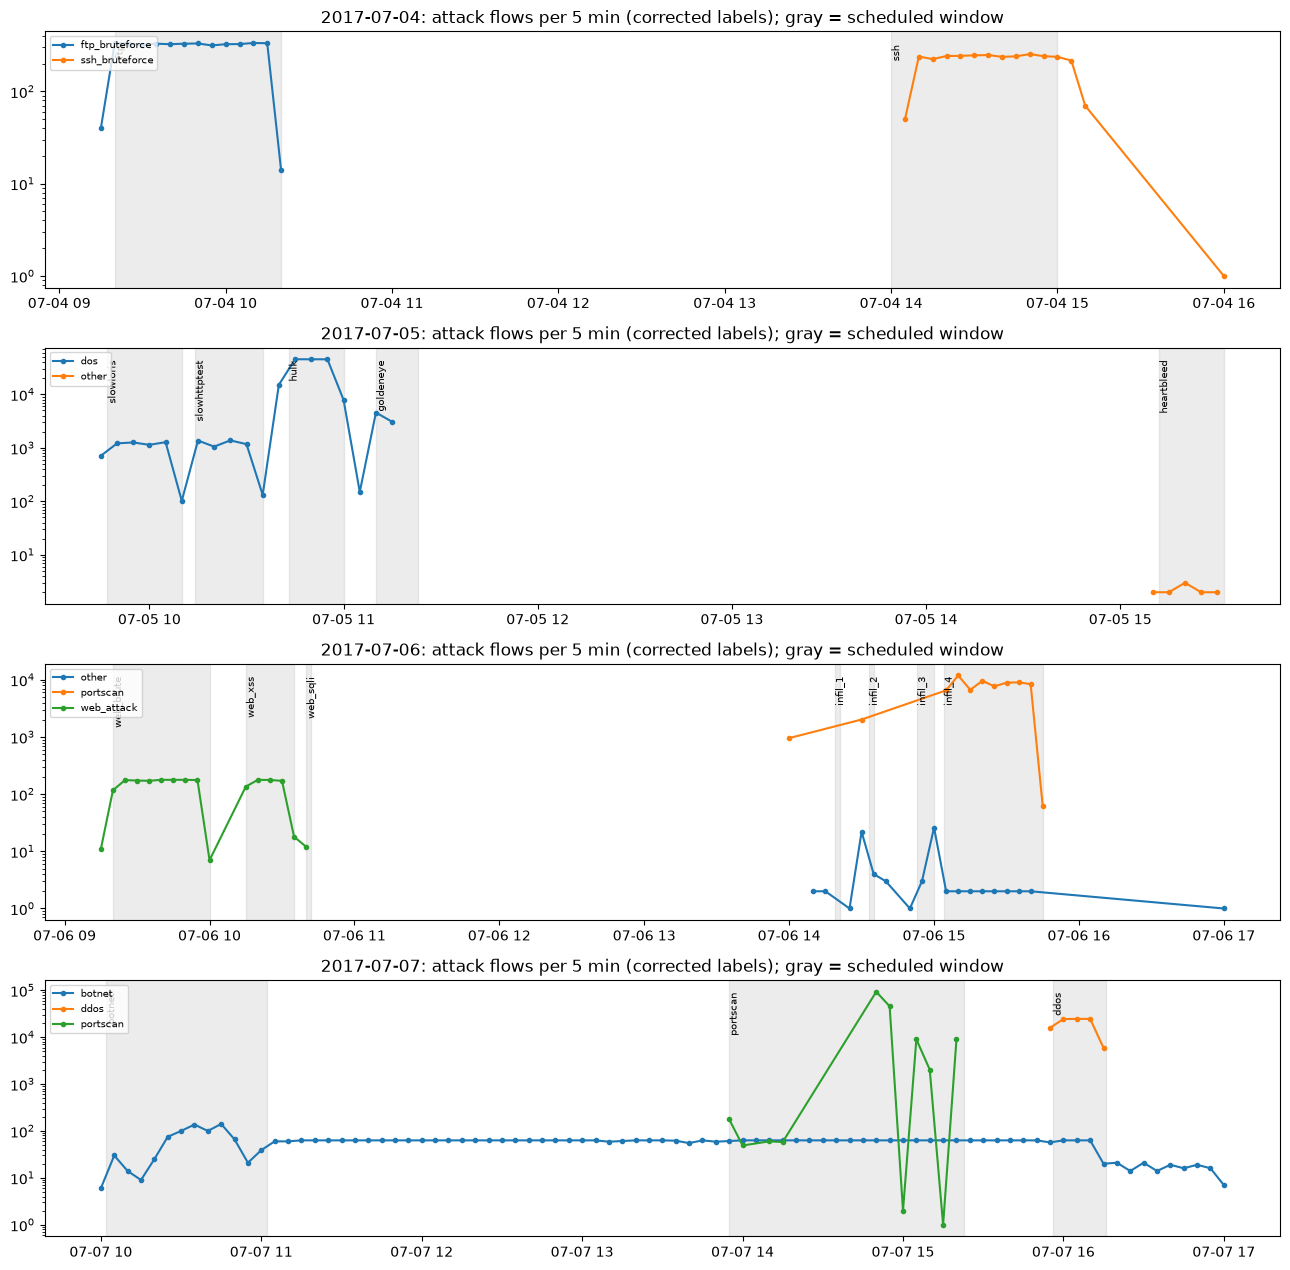

In [4]:
c = corr[~corr.family.isin(["benign", "unmatched", "unknown"])].copy()
c["minute"] = c.timestamp.dt.floor("5min")
days = sorted(c.timestamp.dt.strftime("%Y-%m-%d").unique())

fig, axes = plt.subplots(len(days), 1, figsize=(13, 3.2 * len(days)), squeeze=False)
for ax, d in zip(axes[:, 0], days):
    day = c[c.timestamp.dt.strftime("%Y-%m-%d") == d]
    for fam, g in day.groupby("family"):
        s = g.groupby("minute").size()
        ax.plot(s.index, s.values, marker=".", linestyle="-", label=fam)
    for r in sched[sched.date == d].itertuples():
        ax.axvspan(r.start, r.end, alpha=0.15, color="gray")
        ax.text(r.start, ax.get_ylim()[1] * 0.9, r.id.split("_", 1)[1], fontsize=7, rotation=90, va="top")
    ax.set_yscale("log")
    ax.set_title(f"{d}: attack flows per 5 min (corrected labels); gray = scheduled window")
    ax.legend(fontsize=7, loc="upper left")
plt.tight_layout()
out = ROOT / "results" / "figures" / "timestamp_check_corrected.png"
out.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(out, dpi=130)
plt.show()

In [5]:
print(corr.groupby("family").size().sort_values(ascending=False))
print("attempted flows:", int(corr.attempted.sum()))

family
benign            1582566
portscan           230833
dos                177510
ddos                95144
botnet               4803
ftp_bruteforce       3984
ssh_bruteforce       2988
web_attack           2056
other                  92
dtype: int64
attempted flows: 11979
